In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
pip install imbalanced-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv('data.csv', sep=';')
df.columns = df.columns.str.strip().str.replace('\t','').str.replace('"','')

In [ ]:
#Summary Statistics for All Columns
print("\n📊 Descriptive Statistics (Numerical Only)")
print(df.describe().T)


📊 Descriptive Statistics (Numerical Only)
                                                 count         mean  \
Marital status                                  4424.0     1.178571   
Application mode                                4424.0    18.669078   
Application order                               4424.0     1.727848   
Course                                          4424.0  8856.642631   
Daytime/evening attendance                      4424.0     0.890823   
Previous qualification                          4424.0     4.577758   
Previous qualification (grade)                  4424.0   132.613314   
Nacionality                                     4424.0     1.873192   
Mother's qualification                          4424.0    19.561935   
Father's qualification                          4424.0    22.275316   
Mother's occupation                             4424.0    10.960895   
Father's occupation                             4424.0    11.032324   
Admission grade                   

In [ ]:
#Check for Missing Values
print("\nMissing Values per Column\n")
print(df.isnull().sum())


Missing Values per Column

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                  

In [ ]:
#Unique Values for Categorical Columns
print("\n🧬 Unique Values per Column")
for col in df.columns:
    if df[col].dtype == 'object' or df[col].nunique() < 15:
        print(f"{col}: {df[col].unique()}")


🧬 Unique Values per Column
Marital status: [1 2 4 3 5 6]
Application order: [5 1 2 4 3 6 9 0]
Daytime/evening attendance: [1 0]
Displaced: [1 0]
Educational special needs: [0 1]
Debtor: [0 1]
Tuition fees up to date: [1 0]
Gender: [1 0]
Scholarship holder: [0 1]
International: [0 1]
Curricular units 1st sem (without evaluations): [ 0  1  2  4  3  6 12 10  7  5  8]
Curricular units 2nd sem (without evaluations): [ 0  5  2  1  3  6  4 12  7  8]
Unemployment rate: [10.8 13.9  9.4 16.2 15.5  8.9 12.7 11.1  7.6 12.4]
Inflation rate: [ 1.4 -0.3 -0.8  0.3  2.8  3.7  0.6  2.6  0.5]
GDP: [ 1.74  0.79 -3.12 -0.92 -4.06  3.51 -1.7   2.02  0.32  1.79]
Target: ['Dropout' 'Graduate' 'Enrolled']


In [ ]:
#Unique Values Count
unique_counts = df.nunique()
unique_df = pd.DataFrame({'Column': unique_counts.index, 'Unique Values': unique_counts.values})
print(unique_df)

                                            Column  Unique Values
0                                   Marital status              6
1                                 Application mode             18
2                                Application order              8
3                                           Course             17
4                       Daytime/evening attendance              2
5                           Previous qualification             17
6                   Previous qualification (grade)            101
7                                      Nacionality             21
8                           Mother's qualification             29
9                           Father's qualification             34
10                             Mother's occupation             32
11                             Father's occupation             46
12                                 Admission grade            620
13                                       Displaced              2
14        

In [ ]:
# ==========================================================
# STEP 1: LOAD & CLEAN RAW DATA
# ==========================================================
print("📥 STEP 1: LOAD & CLEAN RAW DATA")
df = pd.read_csv('data.csv', sep=';')
df.columns = df.columns.str.strip().str.replace('\t','').str.replace('"','')

for col in df.columns:
    if df[col].isin(['Graduate', 'Dropout', 'Enrolled']).any():
        df.rename(columns={col: 'Target'}, inplace=True)
        break

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df['Target'] = df['Target'].map({'Graduate': 0, 'Dropout': 1, 'Enrolled': 2})
print(f"✅ Dataset shape after cleaning: {df.shape}")

📥 STEP 1: LOAD & CLEAN RAW DATA
✅ Dataset shape after cleaning: (4424, 37)


In [ ]:
# ==========================================================
# STEP 2: DROP LESS RELEVANT COLUMNS
# ==========================================================
drop_cols = [
    'Curricular units 1st sem (credited)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (without evaluations)',
    'International'
]
df.drop(columns=[col for col in drop_cols if col in df.columns], inplace=True)

In [ ]:
# ==========================================================
# STEP 3: Winsorization (clip outliers)
# ==========================================================
print("📊 STEP 3: CLIP OUTLIERS")
outlier_cols = ['Previous qualification (grade)', 'Admission grade',
                'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
                'Unemployment rate', 'Inflation rate', 'GDP']
for col in outlier_cols:
    if col in df.columns:
        q5, q95 = df[col].quantile([0.05, 0.95])
        df[col] = df[col].clip(lower=q5, upper=q95)
        print(f" - {col}: clipped to [{q5:.2f}, {q95:.2f}]")

📊 STEP 3: CLIP OUTLIERS
 - Previous qualification (grade): clipped to [110.00, 157.00]
 - Admission grade: clipped to [103.42, 153.50]
 - Curricular units 1st sem (grade): clipped to [0.00, 14.86]
 - Curricular units 2nd sem (grade): clipped to [0.00, 14.98]
 - Unemployment rate: clipped to [7.60, 16.20]
 - Inflation rate: clipped to [-0.80, 3.70]
 - GDP: clipped to [-4.06, 3.51]


In [ ]:
# ==========================================================
# STEP 4: Feature Scaling
# ==========================================================
feature_cols = [col for col in df.columns if col != 'Target']
df[feature_cols] = (df[feature_cols] - df[feature_cols].min()) / (df[feature_cols].max() - df[feature_cols].min())
df.fillna(0, inplace=True)
print(f"✅ Features used: {len(feature_cols)} columns\n")

✅ Features used: 31 columns



In [ ]:
# ==========================================================
# STEP 5: TRAIN-TEST SPLIT (80/20)
# ==========================================================
print("📂 STEP 5: SPLIT DATA")
X = df[feature_cols].values
y = df['Target'].values
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[indices[:split]], X[indices[split:]]
y_train, y_test = y[indices[:split]], y[indices[split:]]

📂 STEP 5: SPLIT DATA


📈 STEP 6: OVERSAMPLING WITH SMOTE
✅ After SMOTE: [1747 1747 1747]


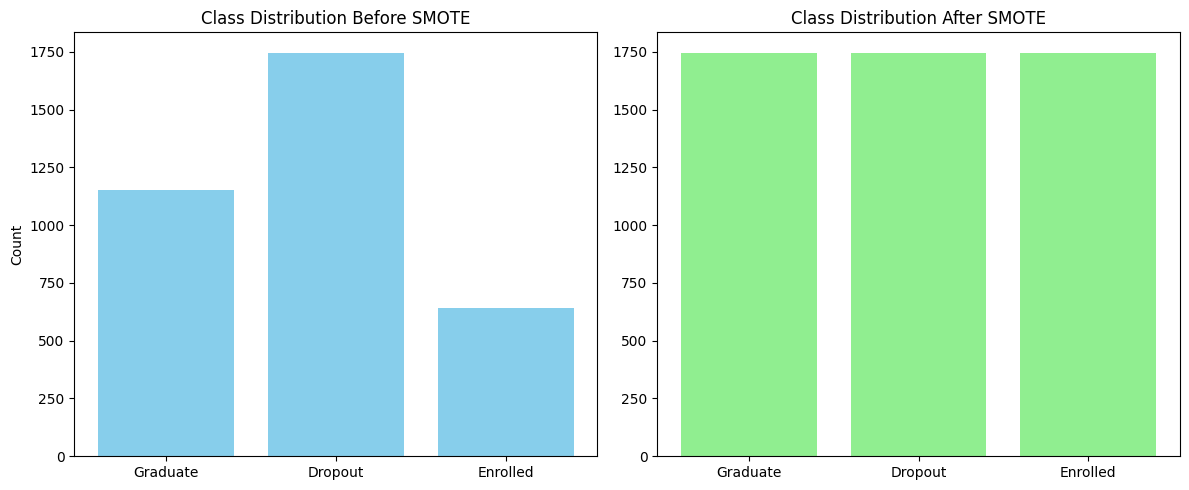

In [ ]:
# ==========================================================
# STEP 6: OVERSAMPLING WITH SMOTE
# ==========================================================
print("📈 STEP 6: OVERSAMPLING WITH SMOTE")
sm = SMOTE(random_state=42)
X_train_os, y_train_os = sm.fit_resample(X_train, y_train)
print(f"✅ After SMOTE: {np.bincount(y_train_os)}")

from collections import Counter
label_names = ['Graduate', 'Dropout', 'Enrolled']

# Before SMOTE
before_counts = Counter(y_train)
before_df = pd.DataFrame.from_dict(before_counts, orient='index', columns=['Count'])
before_df.index = label_names
before_df = before_df.reset_index().rename(columns={'index': 'Class'})

# After SMOTE
after_counts = Counter(y_train_os)
after_df = pd.DataFrame.from_dict(after_counts, orient='index', columns=['Count'])
after_df.index = label_names
after_df = after_df.reset_index().rename(columns={'index': 'Class'})

# 📊 Plotting
plt.figure(figsize=(12, 5))

# Before SMOTE
plt.subplot(1, 2, 1)
plt.bar(before_df['Class'], before_df['Count'], color='skyblue')
plt.title('Class Distribution Before SMOTE')
plt.ylabel('Count')

# After SMOTE
plt.subplot(1, 2, 2)
plt.bar(after_df['Class'], after_df['Count'], color='lightgreen')
plt.title('Class Distribution After SMOTE')

plt.tight_layout()
plt.show()


In [ ]:
# ==========================================================
# STEP 7: ONE-HOT ENCODING
# ==========================================================
def one_hot(y, num_classes=3):
    return np.eye(num_classes)[y]
y_train_oh = one_hot(y_train_os)
y_test_oh = one_hot(y_test)


In [ ]:
# ==========================================================
# STEP 8: DEFINE BPNN MODEL
# ==========================================================
class BPNN:
    def __init__(self, input_size, h1, h2, h3, output_size, lr=0.01):
        self.lr = lr
        self.W1 = np.random.randn(input_size, h1) * np.sqrt(2/input_size)
        self.b1 = np.zeros((1, h1))
        self.W2 = np.random.randn(h1, h2) * np.sqrt(2/h1)
        self.b2 = np.zeros((1, h2))
        self.W3 = np.random.randn(h2, h3) * np.sqrt(2/h2)
        self.b3 = np.zeros((1, h3))
        self.W4 = np.random.randn(h3, output_size) * np.sqrt(2/h3)
        self.b4 = np.zeros((1, output_size))

    def relu(self, x): return np.maximum(0, x)
    def relu_deriv(self, x): return (x > 0).astype(float)
    def softmax(self, x):
        exp = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp / np.sum(exp, axis=1, keepdims=True)

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.relu(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self.relu(self.Z2)
        self.Z3 = self.A2 @ self.W3 + self.b3
        self.A3 = self.relu(self.Z3)
        self.Z4 = self.A3 @ self.W4 + self.b4
        self.A4 = self.softmax(self.Z4)
        return self.A4

    def compute_loss(self, y_true, y_pred):
        return -np.mean(np.sum(y_true * np.log(y_pred + 1e-8), axis=1))

    def backward(self, X, y_true, y_pred):
        m = y_true.shape[0]
        dZ4 = y_pred - y_true
        dW4 = self.A3.T @ dZ4 / m
        db4 = np.sum(dZ4, axis=0, keepdims=True) / m
        dA3 = dZ4 @ self.W4.T
        dZ3 = dA3 * self.relu_deriv(self.Z3)
        dW3 = self.A2.T @ dZ3 / m
        db3 = np.sum(dZ3, axis=0, keepdims=True) / m
        dA2 = dZ3 @ self.W3.T
        dZ2 = dA2 * self.relu_deriv(self.Z2)
        dW2 = self.A1.T @ dZ2 / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m
        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * self.relu_deriv(self.Z1)
        dW1 = X.T @ dZ1 / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        self.W4 -= self.lr * dW4; self.b4 -= self.lr * db4
        self.W3 -= self.lr * dW3; self.b3 -= self.lr * db3
        self.W2 -= self.lr * dW2; self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1; self.b1 -= self.lr * db1

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)


In [ ]:
# ==========================================================
# STEP 9: TRAIN THE MODEL
# ==========================================================
print("🚀 STEP 9: TRAIN MODEL")
model = BPNN(X.shape[1], 256, 128, 64, 3, lr=0.01)
epochs = 1500
losses, train_accs, test_accs = [], [], []
best_acc, patience, wait = 0, 200, 0

for epoch in range(epochs):
    y_pred_train = model.forward(X_train_os)
    loss = model.compute_loss(y_train_oh, y_pred_train)
    model.backward(X_train_os, y_train_oh, y_pred_train)

    acc_train = np.mean(np.argmax(y_pred_train, axis=1) == y_train_os) * 100
    acc_test = np.mean(model.predict(X_test) == y_test) * 100

    losses.append(loss)
    train_accs.append(acc_train)
    test_accs.append(acc_test)

    if acc_test > best_acc:
        best_acc = acc_test
        wait = 0
    else:
        wait += 1

    if loss < 0.001:
        print(f"🛑 Early stopping at epoch {epoch+1} — Loss below 0.001")
        break
    if wait >= patience:
        print(f"🛑 Early stopping at epoch {epoch+1} — Best Test Acc: {best_acc:.2f}%")
        break

    if epoch % 100 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f} - Train Acc: {acc_train:.2f}% - Test Acc: {acc_test:.2f}%")

🚀 STEP 9: TRAIN MODEL
Epoch 1/1500 - Loss: 1.2200 - Train Acc: 24.84% - Test Acc: 17.51%
Epoch 101/1500 - Loss: 0.9383 - Train Acc: 56.69% - Test Acc: 59.21%
Epoch 201/1500 - Loss: 0.8543 - Train Acc: 60.48% - Test Acc: 61.13%
Epoch 301/1500 - Loss: 0.8124 - Train Acc: 62.76% - Test Acc: 62.94%
Epoch 401/1500 - Loss: 0.7855 - Train Acc: 64.61% - Test Acc: 64.63%
Epoch 501/1500 - Loss: 0.7642 - Train Acc: 65.56% - Test Acc: 65.31%
Epoch 601/1500 - Loss: 0.7455 - Train Acc: 66.84% - Test Acc: 67.23%
Epoch 701/1500 - Loss: 0.7288 - Train Acc: 68.10% - Test Acc: 68.14%
Epoch 801/1500 - Loss: 0.7132 - Train Acc: 69.34% - Test Acc: 69.49%
Epoch 901/1500 - Loss: 0.6994 - Train Acc: 70.39% - Test Acc: 69.94%
Epoch 1001/1500 - Loss: 0.6868 - Train Acc: 71.09% - Test Acc: 71.64%
Epoch 1101/1500 - Loss: 0.6754 - Train Acc: 71.55% - Test Acc: 72.77%
Epoch 1201/1500 - Loss: 0.6650 - Train Acc: 71.78% - Test Acc: 72.77%
Epoch 1301/1500 - Loss: 0.6556 - Train Acc: 72.33% - Test Acc: 73.11%
Epoch 1401

In [ ]:
# ==========================================================
# STEP 10: FINAL EVALUATION
# ==========================================================
y_pred_final = model.predict(X_test)
final_acc = np.mean(y_pred_final == y_test) * 100
print(f"\n✅ Final Test Accuracy: {final_acc:.2f}%")


✅ Final Test Accuracy: 73.22%


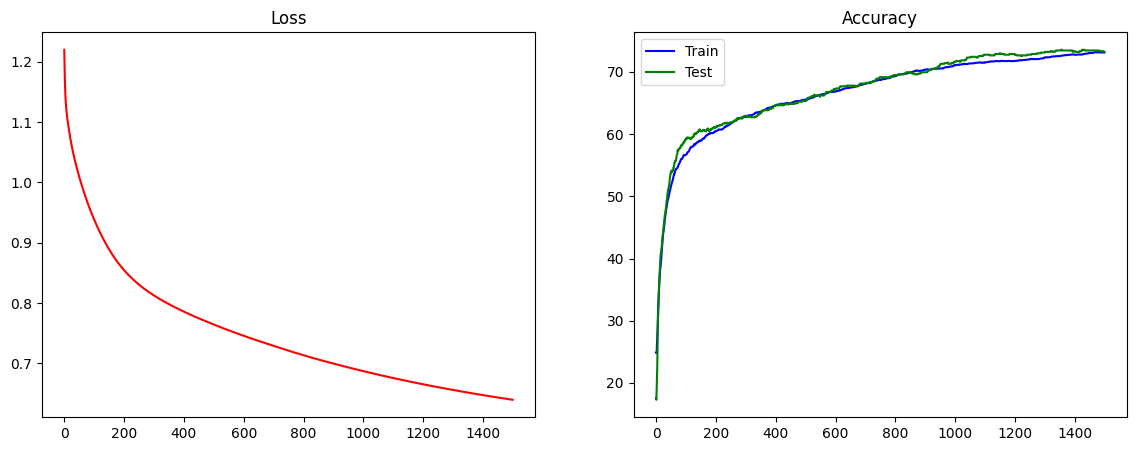

In [ ]:
# ==========================================================
# STEP 11: PLOT LOSS & ACCURACY
# ==========================================================
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(losses, color='red')
plt.title("Loss")
plt.subplot(1,2,2)
plt.plot(train_accs, label="Train", color='blue')
plt.plot(test_accs, label="Test", color='green')
plt.legend()
plt.title("Accuracy")
plt.show()


📊 STEP 12: CONFUSION MATRIX
[[373  13  76]
 [ 26 189  56]
 [ 34  32  86]]


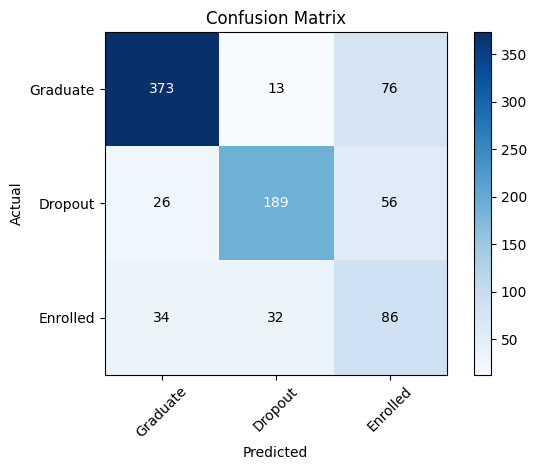

In [ ]:
# ==========================================================
# STEP 12: CONFUSION MATRIX
# ==========================================================
print("📊 STEP 12: CONFUSION MATRIX")
cm = np.zeros((3,3), dtype=int)
for i in range(len(y_test)):
    cm[y_test[i], y_pred_final[i]] += 1
print(cm)

plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(3)
plt.xticks(tick_marks, ['Graduate', 'Dropout', 'Enrolled'], rotation=45)
plt.yticks(tick_marks, ['Graduate', 'Dropout', 'Enrolled'])

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# STEP 13: CLASSIFICATION METRICS & PREDICTION ANALYSIS
# ==========================================================
from sklearn.metrics import classification_report

# 13A: Classification Report
print("\n📊 STEP 13A: CLASSIFICATION REPORT")
report = classification_report(y_test, y_pred_final, target_names=['Graduate', 'Dropout', 'Enrolled'], output_dict=True)
report_df = pd.DataFrame(report).transpose()
display(report_df)

# 13B: Summary Metrics Table
print("\n📋 STEP 13B: SUMMARY METRICS")
summary_df = report_df.loc[['accuracy', 'macro avg', 'weighted avg']].copy()
summary_df.rename(index={
    'accuracy': 'Accuracy (Overall)',
    'macro avg': 'Macro Average',
    'weighted avg': 'Weighted Average'
}, inplace=True)
display(summary_df)

# 13C: Sample Predictions (first 10)
print("\n🔍 STEP 13C: SAMPLE PREDICTIONS")
results_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_final
})
results_df['Actual_Label'] = results_df['Actual'].map({0: 'Graduate', 1: 'Dropout', 2: 'Enrolled'})
results_df['Predicted_Label'] = results_df['Predicted'].map({0: 'Graduate', 1: 'Dropout', 2: 'Enrolled'})
display(results_df.head(10))

# 13D: Best Epoch
print("\n🏅 STEP 13D: BEST EPOCH BY TEST ACCURACY")
best_epoch = np.argmax(test_accs)
best_acc_row = pd.DataFrame({
    'Epoch': [best_epoch + 1],
    'Train Accuracy (%)': [train_accs[best_epoch]],
    'Test Accuracy (%)': [test_accs[best_epoch]],
    'Loss': [losses[best_epoch]]
})
display(best_acc_row)

# 13E: Last 10 Epoch Performance
print("\n📈 STEP 13E: LAST 10 EPOCH PERFORMANCE")
epoch_df = pd.DataFrame({
    'Epoch': np.arange(1, len(train_accs) + 1),
    'Train Accuracy (%)': train_accs,
    'Test Accuracy (%)': test_accs,
    'Loss': losses
})
display(epoch_df.tail(10))



📊 STEP 13A: CLASSIFICATION REPORT


,precision,recall,f1-score,support
Graduate,0.861432,0.807359,0.833520,462.000000
Dropout,0.807692,0.697417,0.748515,271.000000
Enrolled,0.394495,0.565789,0.464865,152.000000
accuracy,0.732203,0.732203,0.732203,0.732203
macro avg,0.687873,0.690189,0.682300,885.000000
weighted avg,0.764779,0.732203,0.744173,885.000000



📋 STEP 13B: SUMMARY METRICS


,precision,recall,f1-score,support
Accuracy (Overall),0.732203,0.732203,0.732203,0.732203
Macro Average,0.687873,0.690189,0.682300,885.000000
Weighted Average,0.764779,0.732203,0.744173,885.000000



🔍 STEP 13C: SAMPLE PREDICTIONS


,Actual,Predicted,Actual_Label,Predicted_Label
0,0,0,Graduate,Graduate
1,0,0,Graduate,Graduate
2,0,2,Graduate,Enrolled
3,0,1,Graduate,Dropout
4,1,0,Dropout,Graduate
5,0,0,Graduate,Graduate
6,0,0,Graduate,Graduate
7,0,0,Graduate,Graduate
8,0,0,Graduate,Graduate
9,0,0,Graduate,Graduate



🏅 STEP 13D: BEST EPOCH BY TEST ACCURACY


,Epoch,Train Accuracy (%),Test Accuracy (%),Loss
0,1355,72.638809,73.559322,0.650891



📈 STEP 13E: LAST 10 EPOCH PERFORMANCE


,Epoch,Train Accuracy (%),Test Accuracy (%),Loss
1490,1491,73.134898,73.333333,0.640018
1491,1492,73.134898,73.333333,0.639944
1492,1493,73.115818,73.333333,0.639869
1493,1494,73.115818,73.333333,0.639794
1494,1495,73.115818,73.333333,0.639720
1495,1496,73.115818,73.333333,0.639646
1496,1497,73.115818,73.220339,0.639571
1497,1498,73.115818,73.220339,0.639497
1498,1499,73.115818,73.220339,0.639423
1499,1500,73.115818,73.220339,0.639349
